# Model development and experiment tracking

Training itself is done by `python -m src.train` (so CI can run it). This notebook documents the process: it reads the MLflow runs, **refits every model from its logged hyper-parameters** to prove the results are reproducible, and produces the comparison plots used in the report.

Prerequisites: `python scripts/download_data.py && python -m src.train`.

In [1]:
import json, sys, warnings
from pathlib import Path

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import clone
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, classification_report
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

from src import data
from src.features import build_preprocessor
from src.train import CANDIDATES, SEED, test_metrics

# src.train selects the Agg backend on import; switch back so plots render here
%matplotlib inline
sns.set_theme(style='whitegrid', palette='deep')
FIG = ROOT / 'report' / 'figures'
FIG.mkdir(parents=True, exist_ok=True)

def save(name):
    plt.tight_layout()
    plt.savefig(FIG / f'{name}.png', dpi=150)
    plt.show()

## 1. Data split

80/20 stratified split with a fixed seed. Model selection and tuning use **only the training split** (5-fold stratified CV); the 20% test split is touched once, for reporting.

In [2]:
df = data.load_clean()
X, y = data.split_xy(df)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print(f'train={len(X_train)}  test={len(X_test)}  positive rate train={y_train.mean():.2f} test={y_test.mean():.2f}')

train=242  test=61  positive rate train=0.46 test=0.46


## 2. What was tracked in MLflow

In [3]:
mlflow.set_tracking_uri(f'sqlite:///{ROOT / "mlflow.db"}')
runs = mlflow.search_runs(experiment_names=['heart-disease-classification'])
cols = ['tags.mlflow.runName', 'metrics.cv_roc_auc', 'metrics.cv_roc_auc_std', 'metrics.cv_accuracy',
        'metrics.cv_precision', 'metrics.cv_recall', 'metrics.test_roc_auc', 'metrics.test_accuracy',
        'metrics.test_precision', 'metrics.test_recall', 'tags.selected']
table = runs[cols].rename(columns=lambda c: c.split('.', 1)[-1]).set_index('mlflow.runName').round(3)
table

,cv_roc_auc,cv_roc_auc_std,cv_accuracy,cv_precision,cv_recall,test_roc_auc,test_accuracy,test_precision,test_recall,selected
mlflow.runName,,,,,,,,,,
gradient_boosting,0.875,0.030,0.793,0.771,0.783,0.951,0.885,0.839,0.929,None
random_forest,0.901,0.023,0.826,0.844,0.774,0.944,0.836,0.821,0.821,None
logistic_regression,0.902,0.014,0.847,0.877,0.783,0.966,0.885,0.839,0.929,true


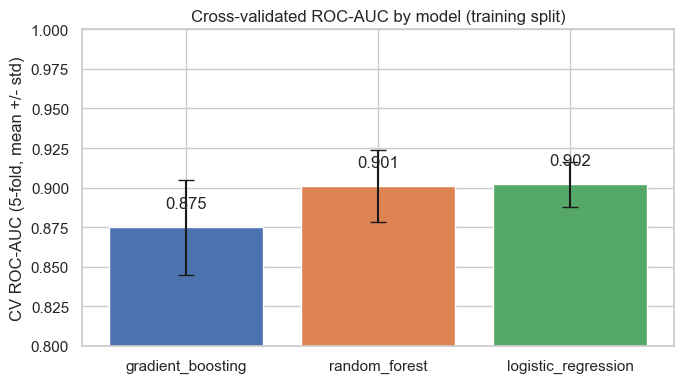

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
t = table.reset_index()
ax.bar(t['mlflow.runName'], t['cv_roc_auc'], yerr=t['cv_roc_auc_std'], capsize=6, color=sns.color_palette()[:3])
ax.set_ylim(0.8, 1.0); ax.set_ylabel('CV ROC-AUC (5-fold, mean +/- std)')
ax.set_title('Cross-validated ROC-AUC by model (training split)')
for i, v in enumerate(t['cv_roc_auc']):
    ax.text(i, v + 0.012, f'{v:.3f}', ha='center')
save('cv_comparison')

Logistic Regression and Random Forest are **statistically tied** on CV ROC-AUC (0.902 vs 0.901, fold-to-fold std 0.014 / 0.023). Logistic Regression is selected because it is marginally ahead, has lower variance, is far simpler and its coefficients are directly interpretable - not because the gap is meaningful.

## 3. Reproducibility check - refit from logged hyper-parameters

In [5]:
metrics = json.loads((ROOT / 'artifacts' / 'metrics.json').read_text())
refit = {}
rows = []
for name, (estimator, _) in CANDIDATES.items():
    pipe = Pipeline([('prep', build_preprocessor()), ('clf', clone(estimator))])
    pipe.set_params(**metrics['models'][name]['params'])
    pipe.fit(X_train, y_train)
    refit[name] = pipe
    got = test_metrics(pipe, X_test, y_test)
    logged = metrics['models'][name]['test_roc_auc']
    rows.append({'model': name, 'refit_test_auc': round(got['roc_auc'], 4), 'mlflow_test_auc': round(logged, 4),
                 'identical': bool(np.isclose(got['roc_auc'], logged))})
pd.DataFrame(rows).set_index('model')

,refit_test_auc,mlflow_test_auc,identical
model,,,
logistic_regression,0.9665,0.9665,True
random_forest,0.9437,0.9437,True
gradient_boosting,0.9513,0.9513,True


## 4. Held-out test evaluation

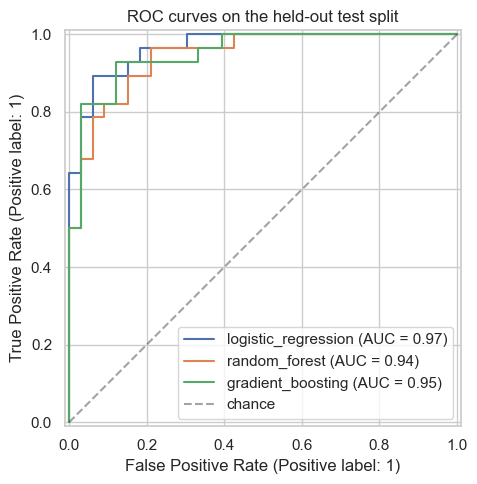

In [6]:
fig, ax = plt.subplots(figsize=(6, 5))
for name, pipe in refit.items():
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], 'k--', alpha=.4, label='chance'); ax.legend(loc='lower right')
ax.set_title('ROC curves on the held-out test split')
save('roc_comparison')

Selected model: logistic_regression


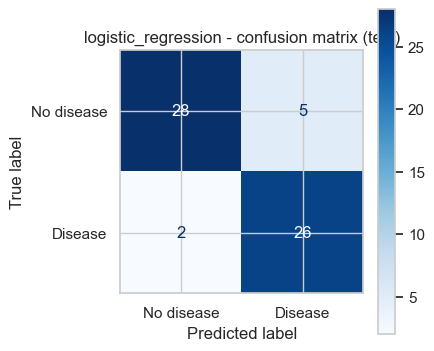

              precision    recall  f1-score   support

  No disease       0.93      0.85      0.89        33
     Disease       0.84      0.93      0.88        28

    accuracy                           0.89        61
   macro avg       0.89      0.89      0.89        61
weighted avg       0.89      0.89      0.89        61



In [7]:
best = metrics['selected_model']
print('Selected model:', best)
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay.from_estimator(refit[best], X_test, y_test, display_labels=['No disease', 'Disease'], ax=ax, cmap='Blues')
ax.set_title(f'{best} - confusion matrix (test)')
save('confusion_matrix')
print(classification_report(y_test, refit[best].predict(X_test), target_names=['No disease', 'Disease']))

With only 61 test patients, one misclassified patient moves accuracy by ~1.6 points, so the test numbers (accuracy 0.885, recall 0.929) should be read together with the cross-validated ones (accuracy 0.847, recall 0.783), which use 242 training patients across 5 folds and are the more trustworthy estimate.

## 5. What drives the prediction

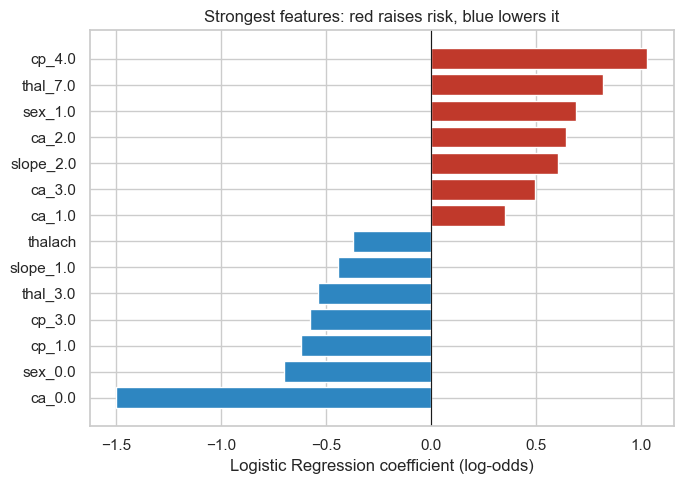

In [8]:
lr = refit['logistic_regression']
names = lr.named_steps['prep'].get_feature_names_out()
coef = pd.Series(lr.named_steps['clf'].coef_[0], index=[n.split('__', 1)[1] for n in names]).sort_values()
top = pd.concat([coef.head(7), coef.tail(7)])
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(top.index, top.values, color=['#c0392b' if v > 0 else '#2e86c1' for v in top.values])
ax.axvline(0, color='k', lw=.8); ax.set_xlabel('Logistic Regression coefficient (log-odds)')
ax.set_title('Strongest features: red raises risk, blue lowers it')
save('lr_coefficients')

Reading the coefficients (all features are one-hot or standardised, so sizes are comparable): having **no** coloured vessels (`ca_0`, -1.50) is by far the strongest protective signal, followed by female sex, a normal thalassemia result (`thal_3`) and a higher maximum heart rate (`thalach`). The strongest risk-raising signals are asymptomatic chest pain (`cp_4`, +1.03), a reversible thalassemia defect (`thal_7`, +0.82), male sex, and one or more coloured vessels (`ca_1`-`ca_3`). Counter-intuitively, typical angina (`cp_1`) is associated with *lower* predicted risk in this dataset; that is a pattern in the Cleveland data, not clinical advice. Coefficients of correlated one-hot columns should not be over-interpreted individually.